# QM640 Medicare Provider Cost Analysis — Final Completion Notebook

**Purpose:** Complete the outstanding analysis needed to update the interim report: data-quality checks, leakage-aware model evaluation, cross-validation on a development sample, RQ1 group comparison with an effect size, RQ3 paired bootstrap comparison of average precision, RQ4 top-k review-capture metrics, and reproducible output files.

**Dataset:** CMS Medicare Physician & Other Practitioners – by Provider (2024)  
**Target:** `Tot_Mdcr_Pymt_Amt`  
**Project repository supplied by the student:** https://github.com/kapildevsharma/ai_ml_medicare-provider-analytics

> **Important:** Run the notebook from top to bottom. The first run should use a smaller development sample to check that the schema and code work. For report-ready results, set `RUN_MODE = "final"` and rerun all cells. Final metrics must be generated from the actual data and saved outputs; do not copy example numbers into the report. Review the CMS data dictionary and manually approve the predictor list before interpreting results. This notebook does not replace a required human review of data definitions, suppression rules, or leakage risk.

## 1. Connect Google Drive and set project paths

If your files are stored in the project folder used earlier, keep the default path below. Change `PROJECT_DIR` if your folder is different.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, warnings, math, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

PROJECT_DIR = Path('/content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project')
DATA_PATH = PROJECT_DIR / 'cms_provider_2024.csv'
OUTPUT_DIR = PROJECT_DIR / 'outputs' / 'final_completion'
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Development run: faster schema/code validation.
# Final run: use all eligible rows, subject to available Colab RAM/runtime.
RUN_MODE = 'development'  # change to 'final' for final report results
DEV_SAMPLE_FRAC = 0.10
RANDOM_STATE = 42

print('Data exists:', DATA_PATH.exists(), DATA_PATH)
print('Output directory:', OUTPUT_DIR)
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f'CSV not found at {DATA_PATH}. Upload cms_provider_2024.csv to this folder '
        'or update DATA_PATH to its actual Drive location.'
    )

Mounted at /content/drive
Data exists: True /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/cms_provider_2024.csv
Output directory: /content/drive/MyDrive/AI_ML-MS/Capstone Project/qm640_project/outputs/final_completion


## 2. Load data and confirm the CMS schema

This cell prints the row/column counts and checks the target and likely group columns. If the target name differs, stop and confirm the correct target from the source data dictionary rather than guessing.

In [2]:
TARGET = 'Tot_Mdcr_Pymt_Amt'
df = pd.read_csv(DATA_PATH, low_memory=False)
df.columns = [str(c).strip() for c in df.columns]

print('Raw shape:', df.shape)
print('First 30 columns:', df.columns.tolist()[:30])
print('Target present:', TARGET in df.columns)
print('Potential provider-group columns:',
      [c for c in df.columns if any(t in c.lower() for t in ['prvdr_type','specialty','gender','state'])])

if TARGET not in df.columns:
    raise KeyError(f'Target {TARGET!r} not found. Inspect df.columns and the official CMS data dictionary.')

# Convert target to numeric and exclude missing/negative target values.
df[TARGET] = pd.to_numeric(df[TARGET], errors='coerce')
n_before = len(df)
df = df.dropna(subset=[TARGET]).loc[lambda x: x[TARGET] >= 0].copy()
print('Rows removed for missing/negative target:', n_before - len(df))
print('Eligible rows:', len(df))

if RUN_MODE == 'development':
    model_df = df.sample(frac=DEV_SAMPLE_FRAC, random_state=RANDOM_STATE).copy()
else:
    model_df = df.copy()
print('Rows used for this run:', len(model_df), '| mode:', RUN_MODE)

schema_summary = pd.DataFrame({
    'column': df.columns,
    'dtype': [str(df[c].dtype) for c in df.columns],
    'missing_count': [int(df[c].isna().sum()) for c in df.columns],
    'missing_pct': [float(df[c].isna().mean()*100) for c in df.columns],
    'n_unique': [int(df[c].nunique(dropna=True)) for c in df.columns]
})
schema_summary.to_csv(OUTPUT_DIR / 'schema_and_missingness.csv', index=False)
schema_summary.sort_values('missing_pct', ascending=False).head(25)

Raw shape: (1296739, 76)
First 30 columns: ['Rndrng_NPI', 'Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'Tot_HCPCS_Cds', 'Tot_Benes', 'Tot_Srvcs', 'Tot_Sbmtd_Chrg', 'Tot_Mdcr_Alowd_Amt', 'Tot_Mdcr_Pymt_Amt', 'Tot_Mdcr_Stdzd_Amt', 'Drug_Sprsn_Ind', 'Drug_Tot_HCPCS_Cds', 'Drug_Tot_Benes', 'Drug_Tot_Srvcs', 'Drug_Sbmtd_Chrg', 'Drug_Mdcr_Alowd_Amt', 'Drug_Mdcr_Pymt_Amt', 'Drug_Mdcr_Stdzd_Amt', 'Med_Sprsn_Ind', 'Med_Tot_HCPCS_Cds', 'Med_Tot_Benes']
Target present: True
Potential provider-group columns: ['Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Type']
Rows removed for missing/negative target: 0
Eligible rows: 1296739
Rows used for this run: 129674 | mode: development


,column,dtype,missing_count,missing_pct,n_unique
27,Med_Sprsn_Ind,object,1145043,88.301732,2
19,Drug_Sprsn_Ind,object,1145043,88.301732,2
44,Bene_Race_API_Cnt,float64,1062540,81.939388,1075
47,Bene_Race_Othr_Cnt,float64,1052600,81.172850,771
45,Bene_Race_Hspnc_Cnt,float64,988886,76.259448,1362
43,Bene_Race_Black_Cnt,float64,924899,71.324993,1526
60,Bene_CC_BH_PTSD_V1_Pct,float64,882169,68.029804,76
51,Bene_CC_BH_ADHD_OthCD_V1_Pct,float64,875024,67.478806,76
59,Bene_CC_BH_PD_V1_Pct,float64,852076,65.709137,76
46,Bene_Race_NatInd_Cnt,float64,848880,65.462672,448


## 3. Data-quality and boundary checks

Use these results to describe what the dataset can and cannot support. This is a diagnostic summary, not proof that every field is valid. Check the CMS dictionary for definitions, units, suppression, and reporting limitations.

{
  "raw_rows": 1296739,
  "eligible_rows_after_target_filter": 1296739,
  "columns": 76,
  "duplicate_rows": 0,
  "target_missing_after_filter": 0,
  "target_negative_after_filter": 0,
  "target_zero_count": 8,
  "target_zero_pct": 0.0006169321659948532,
  "target_min": 0.0,
  "target_median": 26513.0,
  "target_mean": 92584.47359094858,
  "target_p90": 151995.91999999995,
  "target_p95": 261353.12299999932,
  "target_p99": 1141640.4647999995,
  "target_max": 306357782.68
}


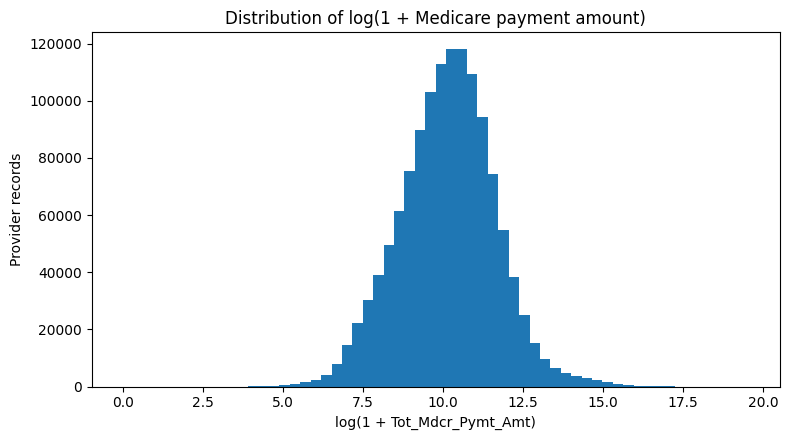

Interpretation prompt: note skew, extreme values, zeros, missingness, duplicates, and any CMS suppression/reporting caveats.


In [3]:
quality = {
    'raw_rows': int(n_before),
    'eligible_rows_after_target_filter': int(len(df)),
    'columns': int(df.shape[1]),
    'duplicate_rows': int(df.duplicated().sum()),
    'target_missing_after_filter': int(df[TARGET].isna().sum()),
    'target_negative_after_filter': int((df[TARGET] < 0).sum()),
    'target_zero_count': int((df[TARGET] == 0).sum()),
    'target_zero_pct': float((df[TARGET] == 0).mean()*100),
    'target_min': float(df[TARGET].min()),
    'target_median': float(df[TARGET].median()),
    'target_mean': float(df[TARGET].mean()),
    'target_p90': float(df[TARGET].quantile(.90)),
    'target_p95': float(df[TARGET].quantile(.95)),
    'target_p99': float(df[TARGET].quantile(.99)),
    'target_max': float(df[TARGET].max()),
}
(OUTPUT_DIR / 'data_quality_summary.json').write_text(json.dumps(quality, indent=2))
print(json.dumps(quality, indent=2))

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(np.log1p(df[TARGET].clip(lower=0)), bins=60)
ax.set_title('Distribution of log(1 + Medicare payment amount)')
ax.set_xlabel('log(1 + Tot_Mdcr_Pymt_Amt)')
ax.set_ylabel('Provider records')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'target_distribution_log1p.png', dpi=160)
plt.show()

print('Interpretation prompt: note skew, extreme values, zeros, missingness, duplicates, and any CMS suppression/reporting caveats.')

## 4. Define and audit the predictor set (leakage prevention)

The model predicts total Medicare payment. Other payment, charge, allowed-amount, standardized-payment, average-payment, and utilization fields may leak the target or act as near-proxies. The automated name screen below is only a starting point. **Inspect the printed columns and the CMS dictionary before accepting the predictors.**

In [4]:
ID_TERMS = {'rndrng_npi', 'npi'}
LEAKAGE_TERMS = (
    'pymt', 'payment', 'alowd', 'allowed', 'chrg', 'charge',
    'stdzd', 'standardized', 'avg_mdcr', 'avg_mcr', 'tot_mdcr',
    'tot_bene', 'tot_srvcs'
)
# The target itself is always excluded from predictors.
candidate_excluded = {
    c for c in model_df.columns
    if c == TARGET or c.lower() in ID_TERMS or any(term in c.lower() for term in LEAKAGE_TERMS)
}
candidate_features = [c for c in model_df.columns if c not in candidate_excluded]

audit = pd.DataFrame({
    'column': model_df.columns,
    'excluded_by_initial_screen': [c in candidate_excluded for c in model_df.columns],
    'reason': [
        'target' if c == TARGET else
        'identifier' if c.lower() in ID_TERMS else
        'possible payment/target leakage' if c in candidate_excluded else
        'candidate predictor - review data dictionary'
        for c in model_df.columns
    ]
})
audit.to_csv(OUTPUT_DIR / 'feature_leakage_audit.csv', index=False)
print('Initially excluded columns:', sorted(candidate_excluded))
print('\nCandidate features to review:', candidate_features)

# Optional manual exclusions: add any columns identified as leakage or inappropriate after dictionary review.
MANUAL_EXCLUDE = []  # e.g. ['column_name']
features = [c for c in candidate_features if c not in MANUAL_EXCLUDE]
print('\nFinal features after manual exclusions:', features)

if not features:
    raise ValueError('No candidate predictors remain. Review the leakage screen and schema.')

Initially excluded columns: ['Drug_Mdcr_Alowd_Amt', 'Drug_Mdcr_Pymt_Amt', 'Drug_Mdcr_Stdzd_Amt', 'Drug_Sbmtd_Chrg', 'Drug_Tot_Benes', 'Drug_Tot_Srvcs', 'Med_Mdcr_Alowd_Amt', 'Med_Mdcr_Pymt_Amt', 'Med_Mdcr_Stdzd_Amt', 'Med_Sbmtd_Chrg', 'Med_Tot_Benes', 'Med_Tot_Srvcs', 'Rndrng_NPI', 'Tot_Benes', 'Tot_Mdcr_Alowd_Amt', 'Tot_Mdcr_Pymt_Amt', 'Tot_Mdcr_Stdzd_Amt', 'Tot_Sbmtd_Chrg', 'Tot_Srvcs']

Candidate features to review: ['Rndrng_Prvdr_Last_Org_Name', 'Rndrng_Prvdr_First_Name', 'Rndrng_Prvdr_Ent_Cd', 'Rndrng_Prvdr_State_Abrvtn', 'Rndrng_Prvdr_State_FIPS', 'Rndrng_Prvdr_Zip5', 'Rndrng_Prvdr_RUCA', 'Rndrng_Prvdr_RUCA_Desc', 'Rndrng_Prvdr_Cntry', 'Rndrng_Prvdr_Type', 'Rndrng_Prvdr_Mdcr_Prtcptg_Ind', 'Tot_HCPCS_Cds', 'Drug_Sprsn_Ind', 'Drug_Tot_HCPCS_Cds', 'Med_Sprsn_Ind', 'Med_Tot_HCPCS_Cds', 'Bene_Avg_Age', 'Bene_Age_LT_65_Cnt', 'Bene_Age_65_74_Cnt', 'Bene_Age_75_84_Cnt', 'Bene_Age_GT_84_Cnt', 'Bene_Feml_Cnt', 'Bene_Male_Cnt', 'Bene_Race_Wht_Cnt', 'Bene_Race_Black_Cnt', 'Bene_Race_API_Cnt'

## 5. Build train/test split and compare regression models

A held-out test set is used for the main performance comparison. The model pipeline imputes missing values and one-hot encodes categoricals without fitting preprocessing on the test set. The model list is intentionally modest for Colab feasibility. If the final run exhausts RAM, reduce high-cardinality categorical columns after reviewing them, or use a stratified/representative documented evaluation sample.

In [5]:
from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier, HistGradientBoostingRegressor
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix
)

X = model_df[features].copy()
y = model_df[TARGET].astype(float).copy()

# Remove columns that contain no usable values or no variation.
X = X.loc[:, X.notna().any(axis=0)]
X = X.loc[:, X.nunique(dropna=True) > 1]
cat_cols = X.select_dtypes(include=['object', 'category', 'bool']).columns.tolist()
num_cols = [c for c in X.columns if c not in cat_cols]
print('Numeric predictors:', num_cols)
print('Categorical predictors:', cat_cols)

# For high-cardinality categoricals, inspect cardinality before proceeding.
cat_cardinality = pd.DataFrame({'column': cat_cols, 'n_unique': [X[c].nunique(dropna=True) for c in cat_cols]})
display(cat_cardinality.sort_values('n_unique', ascending=False))

preprocessor = ColumnTransformer([
    ('numeric', Pipeline([
        ('impute', SimpleImputer(strategy='median')),
        ('scale', StandardScaler())
    ]), num_cols),
    ('categorical', Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('onehot', OneHotEncoder(handle_unknown='ignore', min_frequency=20))
    ]), cat_cols)
], remainder='drop')

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

regression_models = {
    'Median baseline': DummyRegressor(strategy='median'),
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(
        n_estimators=100, min_samples_leaf=10, random_state=RANDOM_STATE, n_jobs=-1
    )
}

reg_rows = []
fitted_regressors = {}
for name, estimator in regression_models.items():
    print('Fitting:', name)
    pipe = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    pipe.fit(X_train, y_train)
    pred = pipe.predict(X_test)
    fitted_regressors[name] = pipe
    reg_rows.append({
        'model': name,
        'n_train': len(X_train),
        'n_test': len(X_test),
        'MAE': float(mean_absolute_error(y_test, pred)),
        'RMSE': float(np.sqrt(mean_squared_error(y_test, pred))),
        'R2': float(r2_score(y_test, pred))
    })

regression_results = pd.DataFrame(reg_rows).sort_values('MAE')
regression_results.to_csv(OUTPUT_DIR / 'regression_metrics.csv', index=False)
display(regression_results)

Numeric predictors: ['Rndrng_Prvdr_RUCA', 'Tot_HCPCS_Cds', 'Drug_Tot_HCPCS_Cds', 'Med_Tot_HCPCS_Cds', 'Bene_Avg_Age', 'Bene_Age_LT_65_Cnt', 'Bene_Age_65_74_Cnt', 'Bene_Age_75_84_Cnt', 'Bene_Age_GT_84_Cnt', 'Bene_Feml_Cnt', 'Bene_Male_Cnt', 'Bene_Race_Wht_Cnt', 'Bene_Race_Black_Cnt', 'Bene_Race_API_Cnt', 'Bene_Race_Hspnc_Cnt', 'Bene_Race_NatInd_Cnt', 'Bene_Race_Othr_Cnt', 'Bene_Dual_Cnt', 'Bene_Ndual_Cnt', 'Bene_Avg_Risk_Scre', 'Bene_CC_BH_ADHD_OthCD_V1_Pct', 'Bene_CC_BH_Alcohol_Drug_V1_Pct', 'Bene_CC_BH_Tobacco_V1_Pct', 'Bene_CC_BH_Alz_NonAlzdem_V2_Pct', 'Bene_CC_BH_Anxiety_V1_Pct', 'Bene_CC_BH_Bipolar_V1_Pct', 'Bene_CC_BH_Mood_V2_Pct', 'Bene_CC_BH_Depress_V1_Pct', 'Bene_CC_BH_PD_V1_Pct', 'Bene_CC_BH_PTSD_V1_Pct', 'Bene_CC_BH_Schizo_OthPsy_V1_Pct', 'Bene_CC_PH_Asthma_V2_Pct', 'Bene_CC_PH_Afib_V2_Pct', 'Bene_CC_PH_Cancer6_V2_Pct', 'Bene_CC_PH_CKD_V2_Pct', 'Bene_CC_PH_COPD_V2_Pct', 'Bene_CC_PH_Diabetes_V2_Pct', 'Bene_CC_PH_HF_NonIHD_V2_Pct', 'Bene_CC_PH_Hyperlipidemia_V2_Pct', 'Bene_CC_P

,column,n_unique
0,Rndrng_Prvdr_Last_Org_Name,57496
1,Rndrng_Prvdr_First_Name,18516
5,Rndrng_Prvdr_Zip5,12746
8,Rndrng_Prvdr_Type,106
4,Rndrng_Prvdr_State_FIPS,60
3,Rndrng_Prvdr_State_Abrvtn,60
6,Rndrng_Prvdr_RUCA_Desc,15
7,Rndrng_Prvdr_Cntry,6
2,Rndrng_Prvdr_Ent_Cd,2
9,Rndrng_Prvdr_Mdcr_Prtcptg_Ind,2


Fitting: Median baseline
Fitting: Linear regression
Fitting: Random forest


,model,n_train,n_test,MAE,RMSE,R2
2,Random forest,103739,25935,53578.404985,592310.669633,0.323093
0,Median baseline,103739,25935,85068.779593,723257.882632,-0.009290
1,Linear regression,103739,25935,124885.223725,459313.725691,0.592949


## 6. Cross-validation on the development data

Cross-validation gives a stability check across folds. To keep runtime reasonable, this cell uses up to 5 folds on the current `model_df`. In `RUN_MODE = "final"`, it may be expensive on a very large dataset; if so, run it on a documented representative sample and explicitly label it as such in the report. Do not present development-sample cross-validation as full-dataset performance.

In [6]:
# CV is performed on a capped representative subset if the full dataset is very large.
CV_MAX_ROWS = 100_000
if len(X) > CV_MAX_ROWS:
    cv_idx = X.sample(n=CV_MAX_ROWS, random_state=RANDOM_STATE).index
    X_cv, y_cv = X.loc[cv_idx], y.loc[cv_idx]
    cv_note = f'CV on representative subset of {CV_MAX_ROWS:,} rows, sampled from {len(X):,} rows.'
else:
    X_cv, y_cv = X, y
    cv_note = f'CV on all {len(X):,} rows available in this run.'

cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_rows = []
for name, estimator in {
    'Linear regression': LinearRegression(),
    'Random forest': RandomForestRegressor(n_estimators=60, min_samples_leaf=10,
                                           random_state=RANDOM_STATE, n_jobs=-1)
}.items():
    pipe = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    print('Cross-validating:', name, '|', cv_note)
    scores = cross_validate(
        pipe, X_cv, y_cv, cv=cv,
        scoring={'mae':'neg_mean_absolute_error', 'r2':'r2'},
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        'model': name, 'folds': 5, 'rows_used': len(X_cv), 'cv_scope': cv_note,
        'MAE_mean': float(-scores['test_mae'].mean()),
        'MAE_sd': float(scores['test_mae'].std(ddof=1)),
        'R2_mean': float(scores['test_r2'].mean()),
        'R2_sd': float(scores['test_r2'].std(ddof=1))
    })
cv_results = pd.DataFrame(cv_rows)
cv_results.to_csv(OUTPUT_DIR / 'cross_validation_metrics.csv', index=False)
display(cv_results)

Cross-validating: Linear regression | CV on representative subset of 100,000 rows, sampled from 129,674 rows.
Cross-validating: Random forest | CV on representative subset of 100,000 rows, sampled from 129,674 rows.


,model,folds,rows_used,cv_scope,MAE_mean,MAE_sd,R2_mean,R2_sd
0,Linear regression,5,100000,"CV on representative subset of 100,000 rows, s...",135735.322139,5990.390252,0.231023,0.127186
1,Random forest,5,100000,"CV on representative subset of 100,000 rows, s...",57575.690149,6105.737423,0.155762,0.179411


## 7. RQ1 — Compare payment amounts between two provider groups

This is an inferential comparison, not a causal analysis. The default group field is provider type if available; the notebook selects the two largest groups. Confirm that this is the comparison defined in your approved research question. If your RQ1 names another grouping variable, change `RQ1_GROUP_COL` and rerun. The test uses Mann–Whitney U and reports a rank-biserial effect-size estimate plus a bootstrap confidence interval for the median difference.

In [7]:
from scipy.stats import mannwhitneyu

group_candidates = [c for c in df.columns if c.lower() in
                    {'rndrng_prvdr_type', 'rndrng_prvdr_gndr', 'rndrng_prvdr_state'}]
print('Suggested group columns:', group_candidates)

RQ1_GROUP_COL = 'Rndrng_Prvdr_Type' if 'Rndrng_Prvdr_Type' in df.columns else (
    group_candidates[0] if group_candidates else None
)
if RQ1_GROUP_COL is None:
    print('No expected group column found. Set RQ1_GROUP_COL manually after inspecting df.columns.')
else:
    r1 = df[[RQ1_GROUP_COL, TARGET]].dropna().copy()
    group_sizes = r1[RQ1_GROUP_COL].value_counts()
    display(group_sizes.head(15))
    # Use the two largest groups for a provisional comparison.
    top_groups = group_sizes.head(2).index.tolist()
    if len(top_groups) < 2:
        raise ValueError('RQ1 needs at least two groups with data.')
    a = r1.loc[r1[RQ1_GROUP_COL] == top_groups[0], TARGET].to_numpy()
    b = r1.loc[r1[RQ1_GROUP_COL] == top_groups[1], TARGET].to_numpy()

    # Mann–Whitney U; exact=False is more robust with ties and larger samples.
    u_stat, p_value = mannwhitneyu(a, b, alternative='two-sided', method='asymptotic')
    # Rank-biserial correlation: 2U/(n1*n2)-1; sign depends on group ordering.
    rank_biserial = 2 * u_stat / (len(a) * len(b)) - 1

    # Bootstrap CI for median difference (group 1 minus group 2).
    rng = np.random.default_rng(RANDOM_STATE)
    B = 2000
    boot_diffs = np.empty(B)
    for i in range(B):
        boot_a = rng.choice(a, size=len(a), replace=True)
        boot_b = rng.choice(b, size=len(b), replace=True)
        boot_diffs[i] = np.median(boot_a) - np.median(boot_b)
    ci_low, ci_high = np.quantile(boot_diffs, [0.025, 0.975])

    rq1_result = {
        'group_column': RQ1_GROUP_COL,
        'group_1': str(top_groups[0]), 'n_group_1': int(len(a)),
        'median_group_1': float(np.median(a)),
        'group_2': str(top_groups[1]), 'n_group_2': int(len(b)),
        'median_group_2': float(np.median(b)),
        'median_difference_group1_minus_group2': float(np.median(a)-np.median(b)),
        'median_difference_bootstrap_95ci': [float(ci_low), float(ci_high)],
        'mann_whitney_U': float(u_stat), 'p_value': float(p_value),
        'rank_biserial_correlation': float(rank_biserial),
        'warning': 'Confirm the group comparison matches the approved RQ1; observational association is not causation.'
    }
    (OUTPUT_DIR / 'rq1_group_comparison.json').write_text(json.dumps(rq1_result, indent=2))
    print(json.dumps(rq1_result, indent=2))

Suggested group columns: ['Rndrng_Prvdr_Type']


,count
Rndrng_Prvdr_Type,
Nurse Practitioner,203212
Physician Assistant,112514
Internal Medicine,93627
Family Practice,83639
Physical Therapist in Private Practice,77901
Certified Registered Nurse Anesthetist (CRNA),53495
Emergency Medicine,50101
Anesthesiology,41082
Diagnostic Radiology,32843


{
  "group_column": "Rndrng_Prvdr_Type",
  "group_1": "Nurse Practitioner",
  "n_group_1": 203212,
  "median_group_1": 13301.49,
  "group_2": "Physician Assistant",
  "n_group_2": 112514,
  "median_group_2": 12626.45,
  "median_difference_group1_minus_group2": 675.039999999999,
  "median_difference_bootstrap_95ci": [
    514.1593749999993,
    822.1864999999992
  ],
  "mann_whitney_U": 11704069956.5,
  "p_value": 1.4229580583249705e-28,
  "rank_biserial_correlation": 0.023790251341072377,
  "warning": "Confirm the group comparison matches the approved RQ1; observational association is not causation."
}


## 8. RQ2 — Identify provider characteristics associated with total Medicare payment variation

**Research question:** Which available provider characteristics are associated with differences in total Medicare payments (`Tot_Mdcr_Pymt_Amt`) among provider records?

**Purpose and interpretation.** RQ2 examines associations, not causal effects. The analysis uses the same leakage-screened predictor set as the regression workflow and a Random Forest regressor fitted only on the training partition. Permutation importance is then measured on the held-out test partition: each original predictor is shuffled in turn, and the increase in mean absolute error (MAE) indicates how much the model's test performance depends on that feature. Larger positive increases indicate greater predictive contribution within this fitted model; values near zero suggest little measured contribution, and negative values can occur from sampling variability or noise.

**Procedure and reporting.**
1. Use the existing train/test split and preprocessing pipeline so imputation and encoding are learned from training data.
2. Use the Random Forest regressor already fitted in the regression section; calculate permutation importance on `X_test` and `y_test`.
3. Repeat each shuffle 10 times and report mean and standard deviation of the increase in MAE, along with the baseline test MAE.
4. Save a ranked CSV and a horizontal bar chart for the 15 most important original predictors.
5. Describe the highest-ranked fields as model-based associations. Do not describe them as causes, and note that correlated predictors can share or mask importance. Review the CMS data dictionary and the leakage audit before interpreting any field.


,importance_rank,feature,mae_increase_mean,mae_increase_sd,baseline_test_MAE,permutation_repeats,n_test_records
13,1,Drug_Tot_HCPCS_Cds,44424.836472,845.623148,53578.404985,10,25935
19,2,Bene_Age_75_84_Cnt,34366.214538,613.958793,53578.404985,10,25935
9,3,Rndrng_Prvdr_Type,14845.317701,120.612461,53578.404985,10,25935
23,4,Bene_Race_Wht_Cnt,13824.239471,297.416449,53578.404985,10,25935
31,5,Bene_Avg_Risk_Scre,13588.883594,463.521292,53578.404985,10,25935
20,6,Bene_Age_GT_84_Cnt,12752.780443,243.832074,53578.404985,10,25935
21,7,Bene_Feml_Cnt,12540.644871,159.674773,53578.404985,10,25935
22,8,Bene_Male_Cnt,10054.131575,150.241055,53578.404985,10,25935
11,9,Tot_HCPCS_Cds,9773.971319,217.562253,53578.404985,10,25935
18,10,Bene_Age_65_74_Cnt,7445.454672,140.636651,53578.404985,10,25935


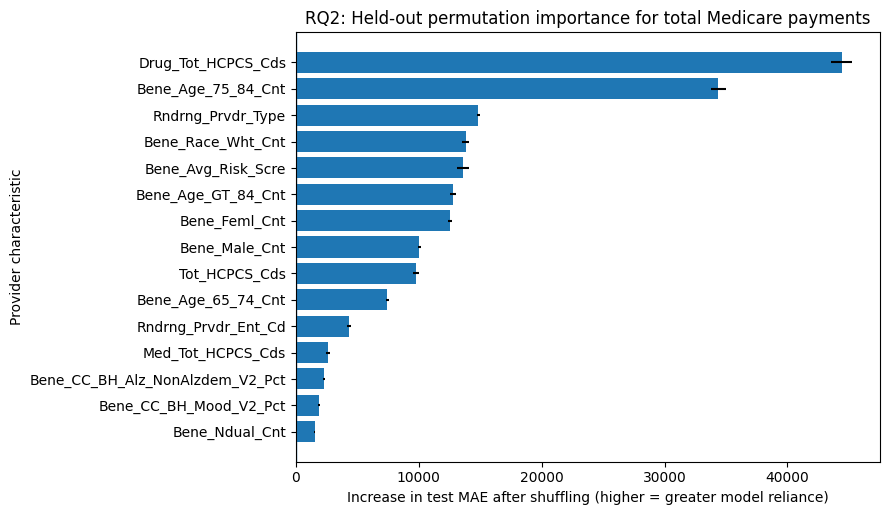

Random Forest baseline test MAE: 53,578.405
Interpretation caution: importance is predictive association, not causal effect.


In [10]:
from sklearn.inspection import permutation_importance

# Use the already fitted Random Forest regression pipeline from the regression section.
# Importance is computed on held-out test data, not the training data.
if 'Random forest' not in fitted_regressors:
    raise RuntimeError("Random Forest regressor is missing. Run the regression-model cell first.")

rq2_model = fitted_regressors['Random forest']
rq2_test_pred = rq2_model.predict(X_test)
rq2_baseline_mae = float(mean_absolute_error(y_test, rq2_test_pred))

rq2_perm = permutation_importance(
    rq2_model,
    X_test,
    y_test,
    scoring='neg_mean_absolute_error',
    n_repeats=10,
    random_state=RANDOM_STATE,
    n_jobs=1
)

rq2_results = pd.DataFrame({
    'feature': X_test.columns,
    # With neg-MAE scoring, positive importance means shuffling increased MAE.
    'mae_increase_mean': rq2_perm.importances_mean,
    'mae_increase_sd': rq2_perm.importances_std,
    'baseline_test_MAE': rq2_baseline_mae,
    'permutation_repeats': 10,
    'n_test_records': len(X_test)
}).sort_values('mae_increase_mean', ascending=False)

rq2_results['importance_rank'] = np.arange(1, len(rq2_results) + 1)
rq2_results = rq2_results[[
    'importance_rank', 'feature', 'mae_increase_mean', 'mae_increase_sd',
    'baseline_test_MAE', 'permutation_repeats', 'n_test_records'
]]
rq2_results.to_csv(OUTPUT_DIR / 'rq2_permutation_importance.csv', index=False)
display(rq2_results.head(25))

# Visualize the 15 highest-ranked original predictors.
plot_data = rq2_results.head(15).sort_values('mae_increase_mean', ascending=True)
fig, ax = plt.subplots(figsize=(9, max(5, 0.35 * len(plot_data))))
ax.barh(plot_data['feature'].astype(str), plot_data['mae_increase_mean'],
        xerr=plot_data['mae_increase_sd'])
ax.axvline(0, linewidth=1)
ax.set_title('RQ2: Held-out permutation importance for total Medicare payments')
ax.set_xlabel('Increase in test MAE after shuffling (higher = greater model reliance)')
ax.set_ylabel('Provider characteristic')
fig.tight_layout()
fig.savefig(OUTPUT_DIR / 'rq2_permutation_importance_top15.png', dpi=160, bbox_inches='tight')
plt.show()

print(f"Random Forest baseline test MAE: {rq2_baseline_mae:,.3f}")
print("Interpretation caution: importance is predictive association, not causal effect.")


## 9. RQ3 — Compare high-cost classification models with paired bootstrap intervals

The high-cost label is defined using the **90th percentile of training-set payment values only** to avoid using test outcomes to set the threshold. Average precision (area under the precision–recall curve) is used because high-cost cases may be imbalanced. The paired bootstrap resamples the same test rows for both models and estimates the difference in average precision. This supports uncertainty reporting; it is not a substitute for a pre-registered minimum meaningful difference.

In [13]:
# Threshold based on training labels only.
high_cost_threshold = float(y_train.quantile(0.90))
y_train_cls = (y_train >= high_cost_threshold).astype(int)
y_test_cls = (y_test >= high_cost_threshold).astype(int)

classification_models = {
    'Prior baseline': DummyClassifier(strategy='prior'),
    'Logistic regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
    'Random forest': RandomForestClassifier(
        n_estimators=100, min_samples_leaf=10, class_weight='balanced_subsample',
        random_state=RANDOM_STATE, n_jobs=-1
    )
}
cls_rows = []
cls_scores = {}
fitted_classifiers = {}
for name, estimator in classification_models.items():
    print('Fitting classifier:', name)
    pipe = Pipeline([('preprocess', preprocessor), ('model', estimator)])
    pipe.fit(X_train, y_train_cls)
    probs = pipe.predict_proba(X_test)[:, 1]
    pred = (probs >= 0.5).astype(int)
    fitted_classifiers[name] = pipe
    cls_scores[name] = probs
    cls_rows.append({
        'model': name, 'threshold_payment': high_cost_threshold,
        'positive_rate_test': float(y_test_cls.mean()),
        'precision_at_0_5': float(precision_score(y_test_cls, pred, zero_division=0)),
        'recall_at_0_5': float(recall_score(y_test_cls, pred, zero_division=0)),
        'F1_at_0_5': float(f1_score(y_test_cls, pred, zero_division=0)),
        'ROC_AUC': float(roc_auc_score(y_test_cls, probs)),
        'average_precision': float(average_precision_score(y_test_cls, probs))
    })
classification_results = pd.DataFrame(cls_rows).sort_values('average_precision', ascending=False)
classification_results.to_csv(OUTPUT_DIR / 'classification_metrics.csv', index=False)
display(classification_results)

# Paired bootstrap CI for AP difference: random forest minus logistic regression, when both are available.
def paired_bootstrap_ap_difference(y_true, score_a, score_b, n_boot=1000, seed=42):
    y_true = np.asarray(y_true)
    score_a = np.asarray(score_a)
    score_b = np.asarray(score_b)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    diffs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, size=n)
        # A bootstrap draw can contain only one class; skip those draws.
        if np.unique(y_true[idx]).size < 2:
            continue
        diffs.append(average_precision_score(y_true[idx], score_a[idx]) -
                     average_precision_score(y_true[idx], score_b[idx]))
    if not diffs:
        return {'difference': None, 'ci95': None, 'successful_bootstraps': 0}
    return {
        'difference': float(average_precision_score(y_true, score_a) - average_precision_score(y_true, score_b)),
        'ci95': [float(np.quantile(diffs, .025)), float(np.quantile(diffs, .975))],
        'successful_bootstraps': int(len(diffs))
    }

y_test_array = y_test_cls.to_numpy()
rq3_comparisons = {}
for model_a, model_b in [('Random forest', 'Logistic regression'),
                         ('Logistic regression', 'Prior baseline'),
                         ('Random forest', 'Prior baseline')]:
    if model_a in cls_scores and model_b in cls_scores:
        rq3_comparisons[f'{model_a} minus {model_b}'] = paired_bootstrap_ap_difference(
            y_test_array, cls_scores[model_a], cls_scores[model_b], n_boot=1000, seed=RANDOM_STATE
        )
(OUTPUT_DIR / 'rq3_paired_ap_bootstrap.json').write_text(json.dumps({
    'threshold_quantile': 0.90,
    'threshold_payment_value': high_cost_threshold,
    'comparisons': rq3_comparisons,
    'note': 'Interpret confidence intervals and practical significance; do not infer causality.'
}, indent=2))
print(json.dumps(rq3_comparisons, indent=2))

Fitting classifier: Prior baseline
Fitting classifier: Logistic regression
Fitting classifier: Random forest


,model,threshold_payment,positive_rate_test,precision_at_0_5,recall_at_0_5,F1_at_0_5,ROC_AUC,average_precision
1,Logistic regression,152865.956,0.099595,0.489782,0.853659,0.622442,0.949204,0.743511
2,Random forest,152865.956,0.099595,0.427452,0.865660,0.572306,0.946537,0.737591
0,Prior baseline,152865.956,0.099595,0.000000,0.000000,0.000000,0.500000,0.099595


{
  "Random forest minus Logistic regression": {
    "difference": -0.005919604551317348,
    "ci95": [
      -0.018835829736731487,
      0.007477518715074277
    ],
    "successful_bootstraps": 1000
  },
  "Logistic regression minus Prior baseline": {
    "difference": 0.6439157729516825,
    "ci95": [
      0.6291149491408435,
      0.6596593230019657
    ],
    "successful_bootstraps": 1000
  },
  "Random forest minus Prior baseline": {
    "difference": 0.6379961684003651,
    "ci95": [
      0.6231593580666827,
      0.6529174003838419
    ],
    "successful_bootstraps": 1000
  }
}


## 10. RQ4 — Top-k review-capacity analysis (capture@k and precision@k)

This analysis asks whether a model can rank high-cost providers near the top when only a limited percentage can be reviewed. It evaluates the top 1%, 5%, and 10% of test records. The label threshold remains the training-set 90th percentile. These are ranking/capacity metrics, not a claim that providers are fraudulent or inappropriate; a high-cost flag should only trigger human review.

In [14]:
def top_k_metrics(y_true, scores, fractions=(0.01, 0.05, 0.10)):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)
    n = len(y_true)
    total_positives = int(y_true.sum())
    order = np.argsort(-scores)
    rows = []
    for frac in fractions:
        k = max(1, int(np.ceil(n * frac)))
        selected = order[:k]
        captured = int(y_true[selected].sum())
        rows.append({
            'review_fraction': frac,
            'n_test_records': n,
            'k_records_reviewed': k,
            'high_cost_cases_total': total_positives,
            'high_cost_cases_captured': captured,
            'capture_at_k': float(captured / total_positives) if total_positives else np.nan,
            'precision_at_k': float(captured / k),
        })
    return rows

rq4_rows = []
for model_name, scores in cls_scores.items():
    for row in top_k_metrics(y_test_array, scores):
        row['model'] = model_name
        rq4_rows.append(row)
rq4_results = pd.DataFrame(rq4_rows)[[
    'model','review_fraction','n_test_records','k_records_reviewed',
    'high_cost_cases_total','high_cost_cases_captured','capture_at_k','precision_at_k'
]]
rq4_results.to_csv(OUTPUT_DIR / 'rq4_topk_review_capture.csv', index=False)
display(rq4_results.sort_values(['review_fraction','capture_at_k'], ascending=[True,False]))

,model,review_fraction,n_test_records,k_records_reviewed,high_cost_cases_total,high_cost_cases_captured,capture_at_k,precision_at_k
6,Random forest,0.01,25935,260,2583,255,0.098722,0.980769
3,Logistic regression,0.01,25935,260,2583,247,0.095625,0.950000
0,Prior baseline,0.01,25935,260,2583,28,0.010840,0.107692
7,Random forest,0.05,25935,1297,2583,1102,0.426636,0.849653
4,Logistic regression,0.05,25935,1297,2583,1096,0.424313,0.845027
1,Prior baseline,0.05,25935,1297,2583,135,0.052265,0.104086
5,Logistic regression,0.10,25935,2594,2583,1792,0.693767,0.690825
8,Random forest,0.10,25935,2594,2583,1720,0.665892,0.663069
2,Prior baseline,0.10,25935,2594,2583,258,0.099884,0.099460


## 11. Sample-size planning: what is calculated and what remains to be finalized

The prior report's preliminary planning values were: RQ1 approximately 63 records per group for a two-sided comparison at α=.05, 80% power, and standardized difference d=.50 (about 66/group allowing 5% exclusions); RQ2 approximately N=118 for 10 predictors, α=.05, 80% power, and medium multiple-regression effect f²=.15. These are assumptions-based planning estimates, not proof that the selected test/model is adequately powered.

For RQ3/RQ4, define the **smallest practically meaningful** AP difference or top-k capture lift, then estimate sample size with pilot-based paired simulation/bootstrap. Do not claim those numeric sample sizes are complete until that simulation is run. This notebook saves pilot results that can be used to plan the simulation, but it does not silently invent a meaningful effect threshold.

In [11]:
sample_size_plan = {
    'RQ1': {
        'assumptions': 'two-sided alpha=.05, power=.80, standardized mean difference d=.50',
        'approx_n_per_group': 63,
        'approx_total_n': 126,
        'with_5pct_exclusions_n_per_group': 66,
        'status': 'provisional; confirm test and target group contrast'
    },
    'RQ2': {
        'assumptions': '10 predictors, alpha=.05, power=.80, medium effect f2=.15',
        'approx_total_n': 118,
        'status': 'provisional; confirm predictor count and model/test'
    },
    'RQ3': {
        'required_next_step': 'Define minimum meaningful paired average-precision difference and run pilot-based paired simulation/bootstrap.',
        'numeric_sample_size': None,
        'status': 'not yet finalized'
    },
    'RQ4': {
        'required_next_step': 'Define minimum meaningful capture@k/precision@k lift at 1%, 5%, and 10% capacity and run paired simulation/bootstrap.',
        'numeric_sample_size': None,
        'status': 'not yet finalized'
    }
}
(OUTPUT_DIR / 'sample_size_plan.json').write_text(json.dumps(sample_size_plan, indent=2))
print(json.dumps(sample_size_plan, indent=2))

{
  "RQ1": {
    "assumptions": "two-sided alpha=.05, power=.80, standardized mean difference d=.50",
    "approx_n_per_group": 63,
    "approx_total_n": 126,
    "with_5pct_exclusions_n_per_group": 66,
    "status": "provisional; confirm test and target group contrast"
  },
  "RQ2": {
    "assumptions": "10 predictors, alpha=.05, power=.80, medium effect f2=.15",
    "approx_total_n": 118,
    "status": "provisional; confirm predictor count and model/test"
  },
  "RQ3": {
    "required_next_step": "Define minimum meaningful paired average-precision difference and run pilot-based paired simulation/bootstrap.",
    "numeric_sample_size": null,
    "status": "not yet finalized"
  },
  "RQ4": {
    "required_next_step": "Define minimum meaningful capture@k/precision@k lift at 1%, 5%, and 10% capacity and run paired simulation/bootstrap.",
    "numeric_sample_size": null,
    "status": "not yet finalized"
  }
}


## 12. Export a run manifest and a report-ready results bundle

The manifest records whether this was a development or final run, the eligible row count, target threshold, test split, feature list, and outputs. Keep it with the report so the results are reproducible.

In [12]:
manifest = {
    'run_timestamp_utc': pd.Timestamp.utcnow().isoformat(),
    'run_mode': RUN_MODE,
    'data_path': str(DATA_PATH),
    'output_dir': str(OUTPUT_DIR),
    'raw_rows': int(n_before),
    'eligible_rows': int(len(df)),
    'rows_used_for_modeling': int(len(model_df)),
    'sample_fraction_used': float(len(model_df) / len(df)),
    'target': TARGET,
    'random_state': RANDOM_STATE,
    'test_fraction': 0.20,
    'high_cost_threshold_quantile': 0.90,
    'high_cost_threshold_value': float(high_cost_threshold),
    'feature_columns_used': X.columns.tolist(),
    'numeric_columns': num_cols,
    'categorical_columns': cat_cols,
    'initial_excluded_columns': sorted(candidate_excluded),
    'manual_exclusions': MANUAL_EXCLUDE,
    'cross_validation_note': cv_note,
    'caution': 'Name-based leakage screening is incomplete; manually review CMS data dictionary and every predictor.'
}
(OUTPUT_DIR / 'run_manifest.json').write_text(json.dumps(manifest, indent=2))

# Copy core result tables into one Excel workbook for convenient report writing.
with pd.ExcelWriter(OUTPUT_DIR / 'final_results_bundle.xlsx', engine='openpyxl') as writer:
    schema_summary.to_excel(writer, sheet_name='Schema_Missingness', index=False)
    regression_results.to_excel(writer, sheet_name='Regression', index=False)
    cv_results.to_excel(writer, sheet_name='Cross_Validation', index=False)
    classification_results.to_excel(writer, sheet_name='Classification', index=False)
    rq4_results.to_excel(writer, sheet_name='TopK_Review', index=False)

print('Completed. Output files:')
for p in sorted(OUTPUT_DIR.iterdir()):
    print('-', p.name, f'({p.stat().st_size:,} bytes)')

Completed. Output files:
- classification_metrics.csv (502 bytes)
- cross_validation_metrics.csv (411 bytes)
- data_quality_summary.json (479 bytes)
- feature_leakage_audit.csv (5,200 bytes)
- final_results_bundle.xlsx (11,483 bytes)
- regression_metrics.csv (291 bytes)
- rq1_group_comparison.json (609 bytes)
- rq2_permutation_importance.csv (5,202 bytes)
- rq2_permutation_importance_top15.png (105,750 bytes)
- rq3_paired_ap_bootstrap.json (839 bytes)
- rq4_topk_review_capture.csv (834 bytes)
- run_manifest.json (4,790 bytes)
- sample_size_plan.json (920 bytes)
- schema_and_missingness.csv (4,183 bytes)
- target_distribution_log1p.png (44,718 bytes)


## 13. How to use these outputs to finish the interim/final report

1. **Data Description / Analysis:** use `data_quality_summary.json`, `schema_and_missingness.csv`, and `target_distribution_log1p.png`. Describe missingness, skew, outliers, duplicates, target boundaries, and the data dictionary limitations.
2. **Model choice and comparison:** use `regression_metrics.csv`, `cross_validation_metrics.csv`, and `classification_metrics.csv`. Report MAE/RMSE/R² for regression and average precision/ROC-AUC plus threshold metrics for classification. State whether cross-validation was run on all rows or a representative subset.
3. **RQ1:** use `rq1_group_comparison.json`; report the exact group names, sample sizes, medians, Mann–Whitney p-value, rank-biserial effect size, and median-difference bootstrap interval. Confirm it matches the approved research question.
4. **RQ3:** use `rq3_paired_ap_bootstrap.json`; report AP differences and 95% bootstrap intervals, and discuss practical rather than only statistical significance.
5. **RQ4:** use `rq4_topk_review_capture.csv`; report capture@k and precision@k at 1%, 5%, and 10% review capacity. Explain that a flag is for human review, not a determination of wrongdoing.
6. **Sample size:** keep RQ1/RQ2 labeled provisional under the stated assumptions. Complete pilot-based sample-size simulations for RQ3/RQ4 before claiming all RQs have numeric power estimates.
7. **Reproducibility:** include `run_manifest.json`, note `RUN_MODE`, and link to the public GitHub repository only after confirming it is accessible and contains the final notebook/scripts.
8. **Final Word report:** update the Table of Contents in Word (right-click TOC → Update Field → Update entire table), refresh figure/table numbers, and verify APA 7 citations and official CMS definitions.

**Final quality gate:** If the output folder contains development-run metrics only, do not call them final results. Change `RUN_MODE = 'final'`, rerun, save the outputs, and document any resource-driven sample restriction transparently.

## 10A. RQ4 uncertainty: bootstrap intervals for top-k capture and precision

The earlier RQ4 table reports point estimates. This additional cell uses paired resampling of the test records to estimate 95% bootstrap intervals for capture@k and precision@k. These intervals describe uncertainty under resampling of this evaluation set; they do not remove dataset bias or replace a preplanned power analysis.

In [15]:
def bootstrap_topk_intervals(y_true, scores, fractions=(0.01, 0.05, 0.10), n_boot=500, seed=42):
    y_true = np.asarray(y_true).astype(int)
    scores = np.asarray(scores)
    rng = np.random.default_rng(seed)
    n = len(y_true)
    out = []
    for frac in fractions:
        captures, precisions = [], []
        for _ in range(n_boot):
            idx = rng.integers(0, n, size=n)
            yt, sc = y_true[idx], scores[idx]
            positives = int(yt.sum())
            k = max(1, int(np.ceil(len(yt) * frac)))
            top = np.argsort(-sc)[:k]
            captured = int(yt[top].sum())
            if positives > 0:
                captures.append(captured / positives)
            precisions.append(captured / k)
        out.append({
            'review_fraction': frac,
            'capture_at_k_ci95_low': float(np.quantile(captures, .025)) if captures else np.nan,
            'capture_at_k_ci95_high': float(np.quantile(captures, .975)) if captures else np.nan,
            'precision_at_k_ci95_low': float(np.quantile(precisions, .025)),
            'precision_at_k_ci95_high': float(np.quantile(precisions, .975)),
            'bootstrap_replicates': n_boot
        })
    return out

rq4_ci_rows = []
for model_name, scores in cls_scores.items():
    for row in bootstrap_topk_intervals(y_test_array, scores, n_boot=500, seed=RANDOM_STATE):
        row['model'] = model_name
        rq4_ci_rows.append(row)
rq4_ci = pd.DataFrame(rq4_ci_rows)
rq4_ci.to_csv(OUTPUT_DIR / 'rq4_topk_bootstrap_intervals.csv', index=False)
display(rq4_ci)


,review_fraction,capture_at_k_ci95_low,capture_at_k_ci95_high,precision_at_k_ci95_low,precision_at_k_ci95_high,bootstrap_replicates,model
0,0.01,0.006578,0.014068,0.065385,0.138462,500,Prior baseline
1,0.05,0.042490,0.057398,0.084040,0.115652,500,Prior baseline
2,0.10,0.089046,0.110191,0.087895,0.111025,500,Prior baseline
3,0.01,0.091401,0.099496,0.911538,0.973077,500,Logistic regression
4,0.05,0.409807,0.437878,0.823439,0.865844,500,Logistic regression
5,0.10,0.679471,0.712270,0.673092,0.711845,500,Logistic regression
6,0.01,0.095223,0.103000,0.965385,0.994327,500,Random forest
7,0.05,0.413205,0.440229,0.828431,0.871646,500,Random forest
8,0.10,0.648434,0.680956,0.641278,0.683520,500,Random forest


## 13. Automated completion checks

Use this cell after all analyses have run. It checks whether the core outputs exist and highlights which claims must remain provisional. This does not verify the correctness of the data dictionary, feature choices, or interpretation; those require manual review.

In [16]:
required_outputs = [
    'data_quality_summary.json',
    'schema_and_missingness.csv',
    'feature_leakage_audit.csv',
    'regression_metrics.csv',
    'cross_validation_metrics.csv',
    'classification_metrics.csv',
    'rq1_group_comparison.json',
    'rq2_permutation_importance.csv',
    'rq2_permutation_importance_top15.png',
    'rq3_paired_ap_bootstrap.json',
    'rq4_topk_review_capture.csv',
    'rq4_topk_bootstrap_intervals.csv',
    'sample_size_plan.json',
    'run_manifest.json',
    'final_results_bundle.xlsx'
]
status_rows = []
for name in required_outputs:
    p = OUTPUT_DIR / name
    status_rows.append({
        'output': name,
        'exists': p.exists(),
        'size_bytes': p.stat().st_size if p.exists() else None
    })
completion_status = pd.DataFrame(status_rows)
display(completion_status)
completion_status.to_csv(OUTPUT_DIR / 'completion_check.csv', index=False)

missing_outputs = completion_status.loc[~completion_status['exists'], 'output'].tolist()
if missing_outputs:
    print('Still missing outputs:', missing_outputs)
else:
    print('All expected output files are present for this run.')

print('\nInterpretation / reporting gates:')
print('1. If RUN_MODE is development, label results as development-only.')
print('2. RQ3/RQ4 sample-size calculations remain incomplete until pilot-based simulations are run.')
print('3. Review the feature audit and CMS data dictionary manually.')
print('4. Confirm RQ1 grouping matches the approved research question.')
print('5. A high-cost prediction indicates review priority only; it does not establish fraud or improper payment.')


,output,exists,size_bytes
0,data_quality_summary.json,True,479
1,schema_and_missingness.csv,True,4183
2,feature_leakage_audit.csv,True,5200
3,regression_metrics.csv,True,291
4,cross_validation_metrics.csv,True,411
5,classification_metrics.csv,True,502
6,rq1_group_comparison.json,True,609
7,rq2_permutation_importance.csv,True,5202
8,rq2_permutation_importance_top15.png,True,105750
9,rq3_paired_ap_bootstrap.json,True,839


All expected output files are present for this run.

Interpretation / reporting gates:
1. If RUN_MODE is development, label results as development-only.
2. RQ3/RQ4 sample-size calculations remain incomplete until pilot-based simulations are run.
3. Review the feature audit and CMS data dictionary manually.
4. Confirm RQ1 grouping matches the approved research question.
5. A high-cost prediction indicates review priority only; it does not establish fraud or improper payment.
